# StreamFlix — Phase 3: KPI Calculations
**Analyst:** Vaishali Sandipsing Girase

**Goal:** Calculate the 10 business KPIs leadership asks about, check each against its target, and add deep-dives on churn, content investment and (bonus) cohort retention.

**Important design choice:** Phase 1 found that ~20% of sessions are dated *after* the subscriber's churn date. Every KPI that depends on sessions is therefore shown **two ways**: using all sessions, and excluding post-churn sessions. This shows which numbers are robust and which are sensitive.

## 0. Setup — load data

In [16]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('charts', exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11})
BLUE, ORANGE, GREY, GREEN, RED = '#2E6FBA', '#F28E2B', '#B8C2CC', '#4CA66B', '#D9534F'

sub = pd.read_csv('subscribers.csv', parse_dates=['signup_date', 'churn_date'])
tit = pd.read_csv('titles.csv', parse_dates=['license_expiry'])
wh  = pd.read_csv('watch_history.csv', parse_dates=['watch_date'])
wl  = pd.read_csv('watchlist.csv')

wh['hours'] = wh.watch_duration_min / 60
wh = wh.merge(sub[['subscriber_id', 'churn_date', 'is_active']], on='subscriber_id', how='left') \
       .merge(tit[['title_id', 'is_original', 'primary_genre']], on='title_id', how='left')
wh['after_churn'] = wh.watch_date > wh.churn_date          # flag from Phase 1
clean = wh[~wh.after_churn]                                  # sessions excluding post-churn

n_total  = len(sub)
n_active = int(sub.is_active.sum())
print('Subscribers:', f'{n_total:,}', '| Active:', f'{n_active:,}')
print('Sessions   :', f'{len(wh):,}', '| of which after churn:', f'{wh.after_churn.sum():,}')

Subscribers: 15,000 | Active: 11,199
Sessions   : 650,000 | of which after churn: 131,199


## KPI 1 — Total Watch Hours
**Formula:** SUM(watch_duration_min) ÷ 60

In [17]:
kpi1_all   = wh.hours.sum()
kpi1_clean = clean.hours.sum()
print(f'Total watch hours (all sessions)           : {kpi1_all:,.0f}')
print(f'Total watch hours (excl. post-churn)       : {kpi1_clean:,.0f}  ({(kpi1_clean/kpi1_all-1)*100:.1f}% vs all)')

Total watch hours (all sessions)           : 3,333,468
Total watch hours (excl. post-churn)       : 2,660,892  (-20.2% vs all)


## KPI 2 — Active Rate  (target > 70%)
**Formula:** Active subscribers ÷ Total subscribers × 100

In [18]:
kpi2 = n_active / n_total * 100
print(f'Active rate: {kpi2:.1f}%   ({n_active:,} of {n_total:,})   -> target > 70%: {"MET" if kpi2 > 70 else "NOT MET"}')

Active rate: 74.7%   (11,199 of 15,000)   -> target > 70%: MET


## KPI 3 — Churn Rate  (target < 30%)
**Formula:** Inactive subscribers ÷ Total subscribers × 100

In [19]:
kpi3 = (~sub.is_active).mean() * 100
print(f'Churn rate: {kpi3:.1f}%   ({n_total - n_active:,} of {n_total:,})   -> target < 30%: {"MET" if kpi3 < 30 else "NOT MET"}')

Churn rate: 25.3%   (3,801 of 15,000)   -> target < 30%: MET


## KPI 4 — Average Completion Rate  (target > 60%)
**Formula:** AVG(completion_pct)

In [20]:
kpi4_all, kpi4_clean = wh.completion_pct.mean(), clean.completion_pct.mean()
print(f'Avg completion (all sessions)     : {kpi4_all:.1f}%   -> target > 60%: {"MET" if kpi4_all > 60 else "NOT MET"}')
print(f'Avg completion (excl. post-churn) : {kpi4_clean:.1f}%')

Avg completion (all sessions)     : 65.3%   -> target > 60%: MET
Avg completion (excl. post-churn) : 65.3%


## KPI 5 — Monthly Recurring Revenue (MRR)
**Formula:** SUM(monthly_price_usd) for *active* subscribers

In [21]:
active = sub[sub.is_active]
kpi5 = active.monthly_price_usd.sum()
print(f'MRR: ${kpi5:,.2f}')
by_plan = active.groupby('plan_type').monthly_price_usd.agg(active_subs='count', mrr='sum')
by_plan['share_of_subs_%'] = (by_plan.active_subs / n_active * 100).round(1)
by_plan['share_of_mrr_%']  = (by_plan.mrr / kpi5 * 100).round(1)
print(by_plan.round(2))

MRR: $175,868.51
                active_subs       mrr  share_of_subs_%  share_of_mrr_%
plan_type                                                             
Basic with Ads         2929  20473.71             26.2            11.6
Premium                3639  83660.61             32.5            47.6
Standard               4631  71734.19             41.4            40.8


## KPI 6 — ARPU (Average Revenue Per User)
**Formula:** MRR ÷ Active subscribers

In [22]:
kpi6 = kpi5 / n_active
print(f'ARPU: ${kpi6:,.2f} per active subscriber per month')

ARPU: $15.70 per active subscriber per month


## KPI 7 — Average Watch Time per Subscriber
**Formula (from the brief):** Total watch hours ÷ Active subscribers

⚠️ The brief's formula puts *all* hours (including hours watched by subscribers who later churned) over only the *active* subscribers, which overstates engagement. So we also show a like-for-like version: hours watched **by active subscribers** ÷ active subscribers.

In [23]:
kpi7_brief = kpi1_all / n_active
kpi7_clean = kpi1_clean / n_active
kpi7_fair  = wh[wh.is_active].hours.sum() / n_active
print(f'Brief formula (all hours / active subs)        : {kpi7_brief:,.1f} hours')
print(f'Brief formula, excl. post-churn sessions       : {kpi7_clean:,.1f} hours')
print(f'Like-for-like (active subs\' own hours / active): {kpi7_fair:,.1f} hours')

Brief formula (all hours / active subs)        : 297.7 hours
Brief formula, excl. post-churn sessions       : 237.6 hours
Like-for-like (active subs' own hours / active): 223.4 hours


## KPI 8 — Watchlist Conversion  (target > 40%)
**Formula:** Watched entries ÷ Watchlist entries × 100

In [24]:
kpi8 = wl.watched.mean() * 100
print(f'Watchlist conversion: {kpi8:.1f}%   ({int(wl.watched.sum()):,} of {len(wl):,})   -> target > 40%: {"MET" if kpi8 > 40 else "NOT MET"}')

Watchlist conversion: 46.2%   (30,048 of 65,000)   -> target > 40%: MET


## KPI 9 — Hit Concentration
**Formula:** Plays from the top 10% of titles ÷ Total plays × 100  (top 10% of 9,000 titles = 900 titles)

In [25]:
def hit_concentration(df):
    plays = df.groupby('title_id').size().sort_values(ascending=False)
    top_n = int(np.ceil(len(tit) * 0.10))
    return plays.head(top_n).sum() / plays.sum() * 100, top_n

kpi9_all,   top_n = hit_concentration(wh)
kpi9_clean, _     = hit_concentration(clean)
print(f'Top {top_n} titles (10%) share of plays — all sessions   : {kpi9_all:.1f}%')
print(f'Top {top_n} titles (10%) share of plays — excl post-churn: {kpi9_clean:.1f}%')
print('Reference: if plays were spread perfectly evenly, the top 10% would hold exactly 10%.')

Top 900 titles (10%) share of plays — all sessions   : 31.0%
Top 900 titles (10%) share of plays — excl post-churn: 30.7%
Reference: if plays were spread perfectly evenly, the top 10% would hold exactly 10%.


## KPI 10 — Originals Share of Hours
**Formula:** Hours on Originals ÷ Total hours × 100

In [26]:
kpi10_all   = wh[wh.is_original].hours.sum() / wh.hours.sum() * 100
kpi10_clean = clean[clean.is_original].hours.sum() / clean.hours.sum() * 100
orig_catalog = tit.is_original.mean() * 100
print(f'Originals share of hours (all sessions)     : {kpi10_all:.1f}%')
print(f'Originals share of hours (excl post-churn)  : {kpi10_clean:.1f}%')
print(f'Originals share of the catalogue (titles)   : {orig_catalog:.1f}%')

Originals share of hours (all sessions)     : 27.2%
Originals share of hours (excl post-churn)  : 26.5%
Originals share of the catalogue (titles)   : 21.8%


## KPI Scorecard — all 10 KPIs in one table

In [27]:
def status(v, target, kind):
    if target is None: return '—'
    ok = v > target if kind == 'gt' else v < target
    return 'Target met' if ok else 'Target NOT met'

kpis = pd.DataFrame([
    ['1. Total Watch Hours',          f'{kpi1_all:,.0f}',           f'{kpi1_clean:,.0f}',  '—',      '—'],
    ['2. Active Rate',                f'{kpi2:.1f}%',               '—',                   '> 70%',  status(kpi2, 70, 'gt')],
    ['3. Churn Rate',                 f'{kpi3:.1f}%',               '—',                   '< 30%',  status(kpi3, 30, 'lt')],
    ['4. Avg Completion Rate',        f'{kpi4_all:.1f}%',           f'{kpi4_clean:.1f}%',  '> 60%',  status(kpi4_all, 60, 'gt')],
    ['5. Monthly Recurring Revenue',  f'${kpi5:,.2f}',              '—',                   '—',      '—'],
    ['6. ARPU',                       f'${kpi6:,.2f}',              '—',                   '—',      '—'],
    ['7. Avg Watch Time / Subscriber (brief formula)', f'{kpi7_brief:,.1f} hrs', f'{kpi7_clean:,.1f} hrs', '—', '—'],
    ['8. Watchlist Conversion',       f'{kpi8:.1f}%',               '—',                   '> 40%',  status(kpi8, 40, 'gt')],
    ['9. Hit Concentration (top 10% titles)', f'{kpi9_all:.1f}%',   f'{kpi9_clean:.1f}%',  '—',      '—'],
    ['10. Originals Share of Hours',  f'{kpi10_all:.1f}%',          f'{kpi10_clean:.1f}%', '—',      '—'],
], columns=['KPI', 'Value (all sessions)', 'Value (excl. post-churn)', 'Target', 'Status'])
print(kpis.to_string(index=False))
kpis.to_csv('kpi_summary.csv', index=False)
print('\nSaved: kpi_summary.csv  (can be used for the Phase 4 dashboard)')

                                           KPI Value (all sessions) Value (excl. post-churn) Target     Status
                          1. Total Watch Hours            3,333,468                2,660,892      —          —
                                2. Active Rate                74.7%                        —  > 70% Target met
                                 3. Churn Rate                25.3%                        —  < 30% Target met
                        4. Avg Completion Rate                65.3%                    65.3%  > 60% Target met
                  5. Monthly Recurring Revenue          $175,868.51                        —      —          —
                                       6. ARPU               $15.70                        —      —          —
7. Avg Watch Time / Subscriber (brief formula)            297.7 hrs                237.6 hrs      —          —
                       8. Watchlist Conversion                46.2%                        —  > 40% Target met
 

### What the scorecard says
- **All four KPIs with targets are met:** active rate 74.7% (> 70%), churn 25.3% (< 30%), completion 65.3% (> 60%), watchlist conversion 46.2% (> 40%).
- **Revenue:** MRR is **$175,868.51** from 11,199 active subscribers, i.e. **ARPU $15.70**. Premium is only 32.5% of active subscribers but brings 47.6% of MRR; Basic with Ads is 26.2% of subscribers and just 11.6% of MRR.
- **Robust vs sensitive numbers:** Ratios barely move when post-churn sessions are removed (completion 65.3% either way, hit concentration 31.0% → 30.7%, Originals share 27.2% → 26.5%). Volumes, however, shrink by about 20% (3.33M → 2.66M hours). Quote ratios with confidence; treat absolute hours with the caveat.
- **Watch time per subscriber:** the brief's formula gives 297.7 hours, but this is inflated because it includes churned users' hours. The like-for-like figure is **223.4 hours** per active subscriber.
- **Hit concentration:** the top 10% of titles (900) account for **31.0% of plays**. That is 3x an even spread but not extreme, so the platform is not dependent on a handful of blockbusters.
- **Originals:** they are 21.8% of the catalogue but generate **27.2% of watch hours**, so they punch above their weight in engagement. The cost side is checked below.

## Deep-dive A — What does an at-risk (churning) subscriber look like?

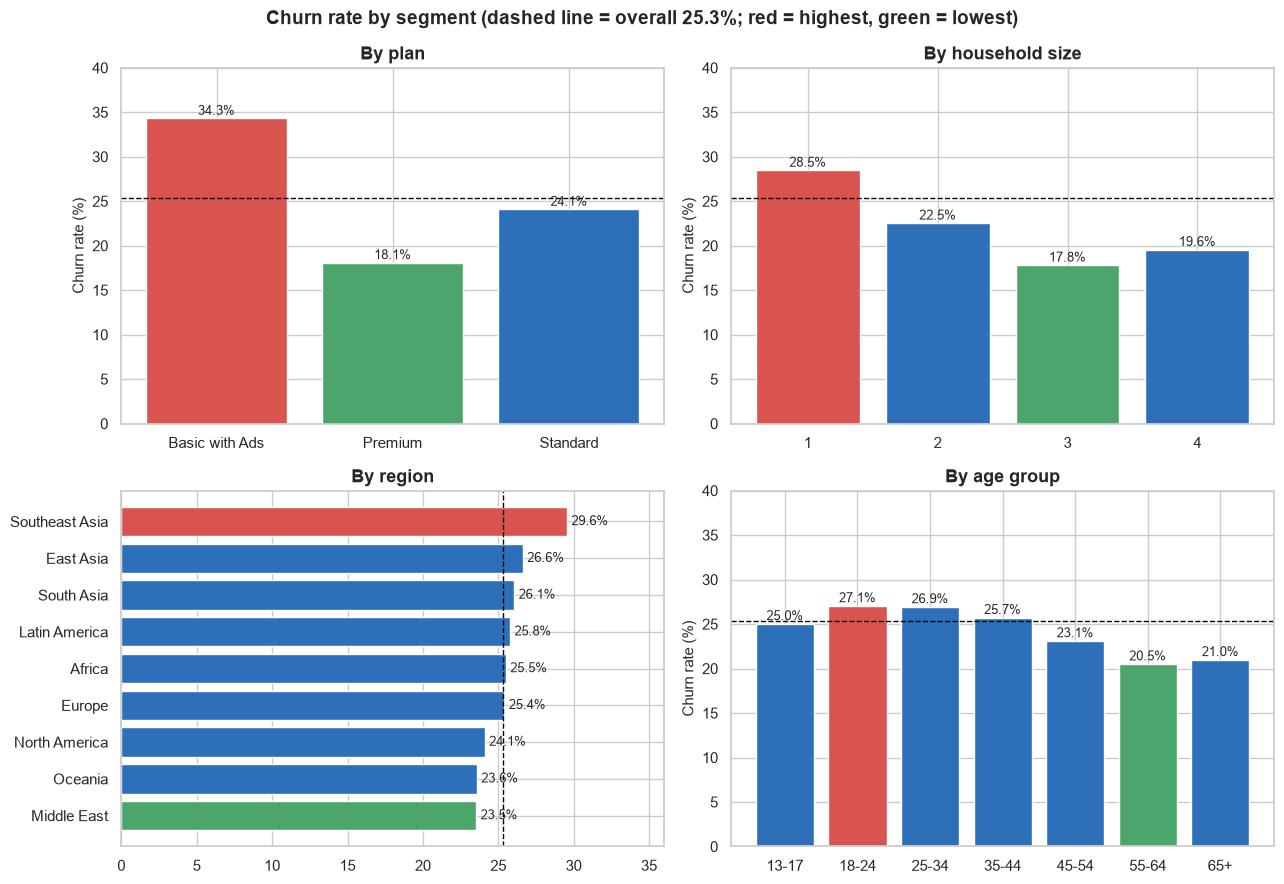

By payment method (%): {'Carrier Billing': 29.5, 'PayPal': 25.8, 'Debit Card': 25.3, 'Credit Card': 25.2, 'Mobile Wallet': 24.6, 'Gift Card': 23.6}


In [28]:
sub['churned'] = ~sub.is_active
sub['age_group'] = pd.cut(sub.age, [12, 17, 24, 34, 44, 54, 64, 100], labels=['13-17','18-24','25-34','35-44','45-54','55-64','65+'])
overall = sub.churned.mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col, title in zip(axes.ravel(), ['plan_type', 'household_size', 'region', 'age_group'],
                          ['By plan', 'By household size', 'By region', 'By age group']):
    r = sub.groupby(col, observed=True).churned.mean() * 100
    if col == 'region': r = r.sort_values()
    colors = [RED if v == r.max() else (GREEN if v == r.min() else BLUE) for v in r.values]
    if col == 'region':
        ax.barh(r.index.astype(str), r.values, color=colors)
        for i, v in enumerate(r.values): ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)
        ax.axvline(overall, color='black', ls='--', lw=1); ax.set_xlim(0, 36)
    else:
        ax.bar(r.index.astype(str), r.values, color=colors)
        for i, v in enumerate(r.values): ax.text(i, v + 0.4, f'{v:.1f}%', ha='center', fontsize=9)
        ax.axhline(overall, color='black', ls='--', lw=1); ax.set_ylim(0, 40)
    ax.set_title(title); ax.set_ylabel('' if col == 'region' else 'Churn rate (%)'); ax.set_xlabel('')
fig.suptitle(f'Churn rate by segment (dashed line = overall {overall:.1f}%; red = highest, green = lowest)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('charts/11_churn_by_segment.png', dpi=150); plt.show()

print('By payment method (%):', (sub.groupby('payment_method').churned.mean() * 100).round(1).sort_values(ascending=False).to_dict())

**Observation — the at-risk profile:** Churn is **34.3% on Basic with Ads versus 18.1% on Premium** (Standard 24.1%): the cheapest plan loses a third of its subscribers. **One-person households churn at 28.5%** versus 17.8% for three-person households, so shared accounts are stickier. **Southeast Asia has the highest regional churn (29.6%)**, and **Carrier Billing users churn at 29.5%** versus about 25% for cards. By age, 18–34 year-olds churn most (about 27%) and 55–64 least (20.5%). An at-risk subscriber is therefore typically young, on Basic with Ads, living alone.

## Deep-dive B — Content investment efficiency (SQL Q12): watch hours per $1,000 of cost

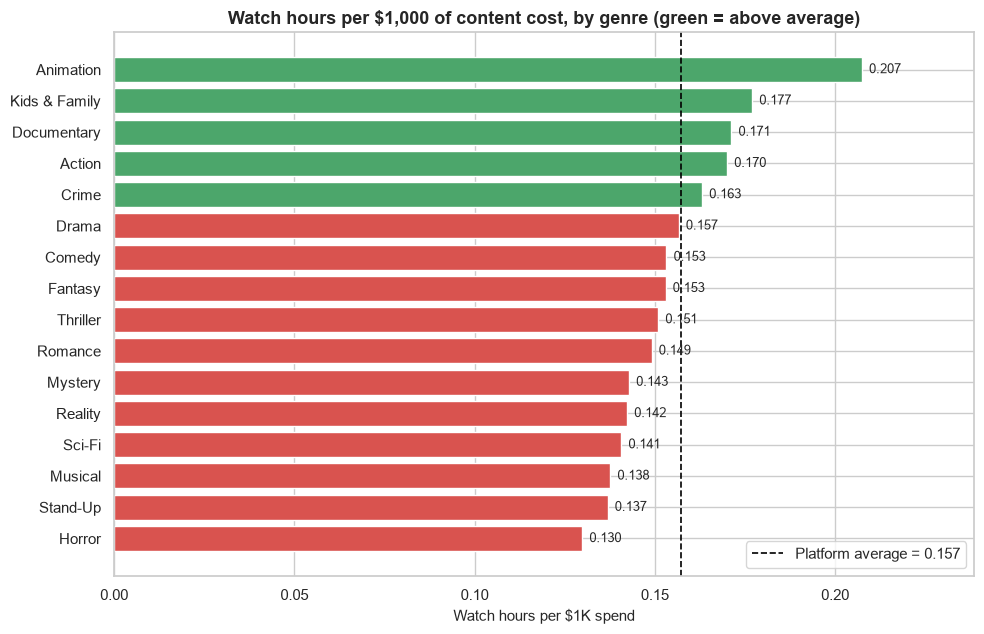

Total content cost: $ 21,214,322,188
               spend_share_%  hours_share_%  hours_per_1k
primary_genre                                            
Animation              4.093          5.403         0.207
Kids & Family          2.747          3.093         0.177
Documentary            8.019          8.736         0.171
Action                10.902         11.795         0.170
Crime                  6.864          7.123         0.163
Drama                 15.108         15.056         0.157
Comedy                13.020         12.694         0.153
Fantasy                3.940          3.835         0.153
Thriller               9.591          9.210         0.151
Romance                6.777          6.430         0.149
Mystery                2.725          2.476         0.143
Reality                3.444          3.119         0.142
Sci-Fi                 5.172          4.630         0.141
Musical                1.337          1.171         0.138
Stand-Up               1.250       

In [29]:
g = tit.groupby('primary_genre').agg(spend=('license_cost_usd', 'sum'), hours=('total_watch_hours', 'sum'), titles=('title_id', 'count'))
g['hours_per_1k'] = g.hours / (g.spend / 1000)
g['spend_share_%'] = g.spend / g.spend.sum() * 100
g['hours_share_%'] = g.hours / g.hours.sum() * 100
g = g.sort_values('hours_per_1k')
avg_eff = tit.total_watch_hours.sum() / (tit.license_cost_usd.sum() / 1000)

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(g.index, g.hours_per_1k, color=[GREEN if v >= avg_eff else RED for v in g.hours_per_1k])
ax.axvline(avg_eff, color='black', ls='--', lw=1.2, label=f'Platform average = {avg_eff:.3f}')
for i, v in enumerate(g.hours_per_1k): ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_title('Watch hours per $1,000 of content cost, by genre (green = above average)')
ax.set_xlabel('Watch hours per $1K spend'); ax.set_ylabel(''); ax.legend(loc='lower right'); ax.set_xlim(0, g.hours_per_1k.max() * 1.15)
plt.tight_layout(); plt.savefig('charts/12_investment_efficiency.png', dpi=150); plt.show()

print('Total content cost: $', f'{tit.license_cost_usd.sum():,.0f}')
print(g.sort_values('hours_per_1k', ascending=False)[['spend_share_%', 'hours_share_%', 'hours_per_1k']].round(3))

o = tit.groupby('is_original').agg(titles=('title_id', 'count'), spend=('license_cost_usd', 'sum'), hours=('total_watch_hours', 'sum'))
o['hours_per_1k'] = o.hours / (o.spend / 1000)
o['spend_share_%'] = o.spend / o.spend.sum() * 100
o['hours_share_%'] = o.hours / o.hours.sum() * 100
o.index = o.index.map({True: 'Original', False: 'Licensed / Co-production'})
print('\nOriginals vs Licensed:'); print(o.round(3))

**Observation:** The platform averages **0.157 watch hours per $1,000** of content cost. **Animation (0.207), Kids & Family (0.177) and Documentary (0.171)** are the most efficient, while **Horror (0.130), Stand-Up (0.137) and Musical (0.138)** are the least, with Horror taking 5.0% of spend but earning only 4.1% of hours. The biggest finding is **Originals**: they absorb **38.4% of all content spend ($8.15B of $21.21B)** but deliver 27.2% of hours, which is **0.111 hours per $1K versus 0.186 for licensed titles (about 40% less)**. Originals have better engagement than their catalogue share, but a worse return per dollar.

## Bonus — Cohort Retention
Subscribers are grouped by **signup month**. For each cohort we check how many were still active **3, 6 and 12 months after signup** (still active = no churn date, or churn date after that point). A cohort is only measured at 3/6/12 months if that much time has passed before the end of the data (31 May 2026).

Monthly cohorts — last 8 cohorts that have a 12-month reading:
              ret_3m  ret_6m  ret_12m
cohort_month                         
2024-10         95.5    93.8     89.3
2024-11         98.3    93.8     85.9
2024-12         97.9    94.2     83.7
2025-01         97.9    95.3     83.7
2025-02         97.1    91.8     82.5
2025-03         97.7    89.8     80.2
2025-04         99.0    92.4     80.7
2025-05         93.7    88.3     75.7

Yearly cohorts:
             subscribers  ret_3m  ret_6m  ret_12m
cohort_year                                      
2016                 237    98.7    97.9     96.2
2017                 569    99.5    98.8     97.2
2018                 836    99.0    98.3     96.1
2019                1055    99.0    97.8     95.8
2020                1349    98.9    97.6     95.3
2021                1583    99.0    97.0     94.3
2022                1736    98.3    96.7     93.6
2023                1944    98.8    96.2     91.0
2024                2175    98.0    94.7

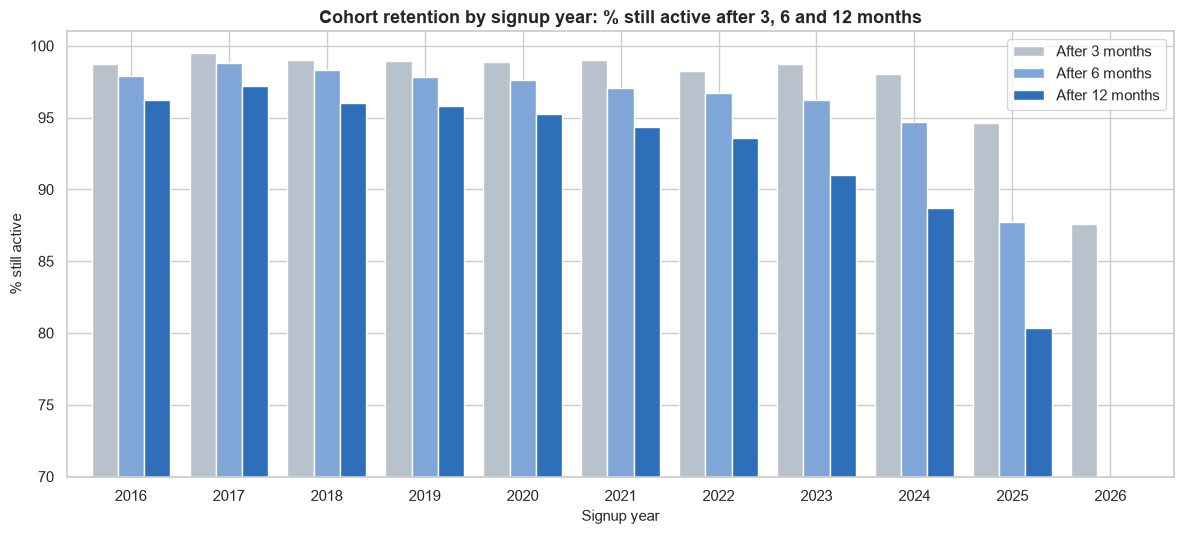

In [30]:
ref = wh.watch_date.max()
sub['cohort_month'] = sub.signup_date.dt.to_period('M')
sub['cohort_year']  = sub.signup_date.dt.year

for n in [3, 6, 12]:
    cutoff = sub.signup_date + pd.DateOffset(months=n)
    still  = (sub.churn_date.isna() | (sub.churn_date > cutoff)).astype(float)
    sub[f'ret_{n}m'] = still.where(cutoff <= ref)      # NaN if not enough time has passed

monthly = sub.groupby('cohort_month')[['ret_3m', 'ret_6m', 'ret_12m']].mean() * 100
print('Monthly cohorts — last 8 cohorts that have a 12-month reading:')
print(monthly.dropna().tail(8).round(1))

yearly = sub.groupby('cohort_year').agg(subscribers=('subscriber_id', 'count'),
                                        ret_3m=('ret_3m', 'mean'), ret_6m=('ret_6m', 'mean'), ret_12m=('ret_12m', 'mean'))
yearly[['ret_3m', 'ret_6m', 'ret_12m']] *= 100
print('\nYearly cohorts:'); print(yearly.round(1))

fig, ax = plt.subplots(figsize=(12, 5.5))
yearly[['ret_3m', 'ret_6m', 'ret_12m']].plot(kind='bar', ax=ax, color=[GREY, '#7FA6D6', BLUE], width=0.8)
ax.set_title('Cohort retention by signup year: % still active after 3, 6 and 12 months')
ax.set_xlabel('Signup year'); ax.set_ylabel('% still active'); ax.set_ylim(70, 101)
ax.legend(['After 3 months', 'After 6 months', 'After 12 months'], loc='upper right')
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig('charts/13_cohort_retention.png', dpi=150); plt.show()

**Observation:** Retention is very high for older cohorts but is **getting worse for newer ones**. The 12-month retention was 96.2% for 2016 signups and 91.0% for 2023, but **only 80.4% for 2025 signups**; the 3-month retention of the 2026 cohort is 87.6% versus about 99% for older cohorts. Since subscriber sign-ups keep growing every year (2,457 in 2025), the business is acquiring more users but **keeping a smaller share of them**, so early-life churn is the biggest retention risk.

## Phase 3 — Key findings
1. **Overall health is good:** all four KPIs with a target meet it (active 74.7%, churn 25.3%, completion 65.3%, watchlist conversion 46.2%).
2. **Revenue is concentrated in Premium:** 32.5% of active subscribers give 47.6% of MRR (total MRR $175,869, ARPU $15.70), and Premium also has the lowest churn (18.1%).
3. **Churn is a Basic-with-Ads and new-customer problem:** 34.3% churn on Basic, and 12-month retention fell from ~96% (older cohorts) to 80.4% (2025 cohort).
4. **Originals are engaging but expensive:** 38.4% of spend, 27.2% of hours, ~40% less watch time per dollar than licensed content.
5. **Genre efficiency differs:** Animation, Kids & Family and Documentary give the most hours per dollar; Horror, Stand-Up and Musical the least.
6. **Data caveat:** ~20% of sessions fall after churn dates. Ratios are stable either way; absolute hour totals are about 20% lower without them.

**Next:** Phase 4 — a 5-page dashboard (Power BI or Excel) and the management report for the CEO.